In [ ]:
!pip install timm seaborn scikit-learn --quiet

In [ ]:
import os, copy, time
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import datasets, transforms
import timm

from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [ ]:
class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        mid = max(channels // reduction, 8)
        self.mlp = nn.Sequential(
            nn.Linear(channels, mid, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(mid, channels, bias=False),
        )

    def forward(self, x):
        avg = x.mean(dim=[2, 3])
        mx = x.amax(dim=[2, 3])
        return torch.sigmoid(self.mlp(avg) + self.mlp(mx)).unsqueeze(-1).unsqueeze(-1)


class SpatialAttention(nn.Module):
    def __init__(self, kernel=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel, padding=kernel//2, bias=False)

    def forward(self, x):
        cat = torch.cat([x.mean(dim=1, keepdim=True),
                         x.amax(dim=1, keepdim=True)], dim=1)
        return torch.sigmoid(self.conv(cat))


class CBAM(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.ca = ChannelAttention(channels)
        self.sa = SpatialAttention()

    def forward(self, x):
        x = x * self.ca(x)
        x = x * self.sa(x)
        return x

In [ ]:
class AccidentDetector(nn.Module):
    BACKBONE_CHANNELS = 1536

    def __init__(self, num_classes=2, pretrained=True, dropout=0.4):
        super().__init__()
        self.backbone = timm.create_model(
            "efficientnet_b3",
            pretrained=pretrained,
            num_classes=0,
            global_pool=""
        )
        self.cbam = CBAM(self.BACKBONE_CHANNELS)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(self.BACKBONE_CHANNELS, num_classes)

    def forward(self, x):
        feat = self.backbone.forward_features(x)
        feat = self.cbam(feat)
        feat = self.pool(feat).flatten(1)
        feat = self.dropout(feat)
        return self.head(feat)

In [ ]:
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, label_smoothing=0.1, weight=None):
        super().__init__()
        self.gamma = gamma
        self.ls = label_smoothing
        self.weight = weight

    def forward(self, logits, targets):
        num_cls = logits.size(1)

        with torch.no_grad():
            smooth_targets = torch.full_like(logits, self.ls / (num_cls - 1))
            smooth_targets.scatter_(1, targets.unsqueeze(1), 1.0 - self.ls)

        log_probs = F.log_softmax(logits, dim=1)
        probs = log_probs.exp()
        focal_w = (1.0 - probs) ** self.gamma

        loss = -(smooth_targets * focal_w * log_probs).sum(dim=1)

        if self.weight is not None:
            loss *= self.weight[targets]

        return loss.mean()

In [ ]:
INPUT_SIZE = 300

def make_transforms():
    mean = [0.485, 0.456, 0.406]
    std  = [0.229, 0.224, 0.225]

    train_tf = transforms.Compose([
        transforms.Resize((INPUT_SIZE, INPUT_SIZE)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(10),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])

    val_tf = transforms.Compose([
        transforms.Resize((INPUT_SIZE, INPUT_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])

    return train_tf, val_tf


def load_data(data_dir, batch_size=32):
    train_tf, val_tf = make_transforms()

    train_ds = datasets.ImageFolder(Path(data_dir) / "train", transform=train_tf)
    test_ds  = datasets.ImageFolder(Path(data_dir) / "test", transform=val_tf)

    sampler = WeightedRandomSampler(
        [1.0 / np.bincount([s[1] for s in train_ds.samples])[s[1]]
         for s in train_ds.samples],
        len(train_ds),
        replacement=True
    )

    train_loader = DataLoader(train_ds, batch_size=batch_size, sampler=sampler)
    test_loader  = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

    return train_loader, test_loader, train_ds.classes

In [ ]:
def train(model, train_loader, test_loader, device, epochs=20):

    counts = np.bincount([s[1] for s in train_loader.dataset.samples])
    weights = torch.tensor(counts.sum() / (len(counts) * counts), dtype=torch.float32).to(device)

    criterion = FocalLoss(weight=weights)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)

    for epoch in range(epochs):
        print(f"\nEpoch {epoch+1}/{epochs}")

        for phase, loader in [("train", train_loader), ("val", test_loader)]:
            model.train() if phase == "train" else model.eval()

            total_loss = 0
            correct = 0
            total = 0

            for imgs, labels in loader:
                imgs, labels = imgs.to(device), labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == "train"):
                    outputs = model(imgs)
                    loss = criterion(outputs, labels)

                    if phase == "train":
                        loss.backward()
                        optimizer.step()

                total_loss += loss.item() * imgs.size(0)
                correct += (outputs.argmax(1) == labels).sum().item()
                total += imgs.size(0)

            print(f"{phase} loss: {total_loss/total:.4f} acc: {correct/total:.4f}")

In [ ]:
def evaluate(model, loader, device, class_names):
    model.eval()
    preds, gts = [], []

    with torch.no_grad():
        for imgs, labels in loader:
            outputs = model(imgs.to(device))
            preds.extend(outputs.argmax(1).cpu().numpy())
            gts.extend(labels.numpy())

    print(confusion_matrix(gts, preds))
    print(classification_report(gts, preds, target_names=class_names))

In [ ]:
import kagglehub
path = kagglehub.dataset_download("ckay16/accident-detection-from-cctv-footage")

Using Colab cache for faster access to the 'accident-detection-from-cctv-footage' dataset.


In [ ]:
path

'/kaggle/input/accident-detection-from-cctv-footage'

In [ ]:
DATA_DIR = path+"/data"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_loader, test_loader, class_names = load_data(DATA_DIR)

model = AccidentDetector().to(device)

train(model, train_loader, test_loader, device, epochs=20)


Epoch 1/20
train loss: 0.1469 acc: 0.7623
val loss: 0.1276 acc: 0.8400

Epoch 2/20
train loss: 0.1255 acc: 0.8609
val loss: 0.1118 acc: 0.9500

Epoch 3/20
train loss: 0.1098 acc: 0.9355
val loss: 0.1039 acc: 0.9600

Epoch 4/20
train loss: 0.1076 acc: 0.9482
val loss: 0.1047 acc: 0.9500

Epoch 5/20
train loss: 0.1050 acc: 0.9507
val loss: 0.1060 acc: 0.9400

Epoch 6/20
train loss: 0.0989 acc: 0.9709
val loss: 0.1034 acc: 0.9600

Epoch 7/20
train loss: 0.0978 acc: 0.9747
val loss: 0.0982 acc: 0.9700

Epoch 8/20
train loss: 0.0975 acc: 0.9798
val loss: 0.1006 acc: 0.9600

Epoch 9/20
train loss: 0.0982 acc: 0.9697
val loss: 0.0959 acc: 0.9800

Epoch 10/20
train loss: 0.0991 acc: 0.9671
val loss: 0.0971 acc: 0.9800

Epoch 11/20
train loss: 0.0954 acc: 0.9823
val loss: 0.1000 acc: 0.9700

Epoch 12/20
train loss: 0.0960 acc: 0.9798
val loss: 0.0974 acc: 0.9800

Epoch 13/20
train loss: 0.0936 acc: 0.9899
val loss: 0.0967 acc: 0.9700

Epoch 14/20
train loss: 0.0927 acc: 0.9874
val loss: 0.0980

In [ ]:
evaluate(model, test_loader, device, class_names)

[[45  2]
 [ 0 53]]
              precision    recall  f1-score   support

    Accident       1.00      0.96      0.98        47
Non Accident       0.96      1.00      0.98        53

    accuracy                           0.98       100
   macro avg       0.98      0.98      0.98       100
weighted avg       0.98      0.98      0.98       100



In [ ]:
model_save_path = '/content/drive/MyDrive/accident_detector_model.pth'
torch.save(model.state_dict(), model_save_path)
print(f"Model saved to {model_save_path}")

Model saved to /content/drive/MyDrive/accident_detector_model.pth


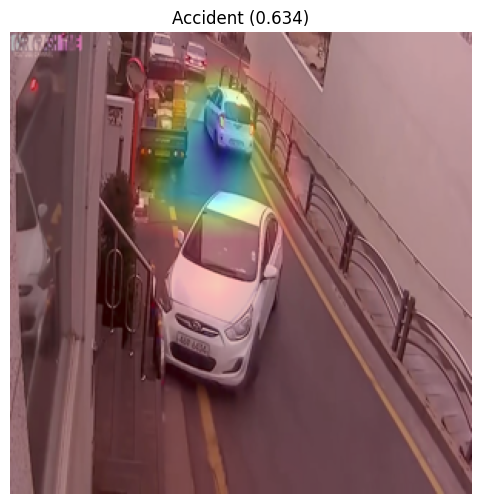

In [ ]:
# =========================
# Grad-CAM (HOOK-FREE FINAL)
# =========================

import torch
import torch.nn.functional as F
import numpy as np
import cv2
import matplotlib.pyplot as plt
from torchvision import transforms
from PIL import Image

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer

        self.activations = None

        # Only forward hook (safe)
        self.target_layer.register_forward_hook(self.forward_hook)

    def forward_hook(self, module, input, output):
        self.activations = output

    def generate(self, input_tensor, class_idx=None):
        self.model.eval()

        output = self.model(input_tensor)

        if class_idx is None:
            class_idx = output.argmax(dim=1)

        # Get gradients w.r.t. activations
        grads = torch.autograd.grad(
            outputs=output[:, class_idx],
            inputs=self.activations,
            grad_outputs=torch.ones_like(output[:, class_idx]),
            retain_graph=True,
            create_graph=False
        )[0]

        activations = self.activations

        weights = grads.mean(dim=(2, 3), keepdim=True)
        cam = (weights * activations).sum(dim=1)

        cam = torch.relu(cam)
        cam = cam.squeeze().detach().cpu().numpy()

        cam = (cam - cam.min()) / (cam.max() + 1e-8)

        return cam


def show_gradcam(image_path, model, device, class_names):
    img = Image.open(image_path).convert("RGB")

    transform = transforms.Compose([
        transforms.Resize((300, 300)),
        transforms.ToTensor(),
    ])

    input_tensor = transform(img).unsqueeze(0).to(device)

    gradcam = GradCAM(model, model.cbam)
    cam = gradcam.generate(input_tensor)

    # Resize CAM
    cam = cv2.resize(cam, (300, 300))

    img_np = np.array(img.resize((300, 300)))

    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    overlay = heatmap * 0.4 + img_np
    overlay = overlay / overlay.max()

    # Prediction
    model.eval()
    with torch.no_grad():
        output = model(input_tensor)
        probs = F.softmax(output, dim=1)[0]
        pred = probs.argmax().item()

    plt.figure(figsize=(6,6))
    plt.imshow(overlay)
    plt.title(f"{class_names[pred]} ({probs[pred]:.3f})")
    plt.axis("off")
    plt.show()


# =========================
# RUN
# =========================

show_gradcam(
    path+"/data/train/Accident/test10_11.jpg",
    model,
    device,
    class_names
)

In [ ]:
!pip install streamlit


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 70.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 93.5 MB/s eta 0:00:00


In [ ]:

code = """
import streamlit as st
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
import tempfile
import timm

st.set_page_config(layout="wide")
st.title("🚗 Accident Detection with Grad-CAM")

# -------------------- CONFIG --------------------
MODEL_PATH = "/content/drive/MyDrive/accident_detector_model.pth"  # change this

# -------------------- LOAD MODEL --------------------
@st.cache_resource
def load_model():
    model = timm.create_model("efficientnet_b3", pretrained=False)

    # binary classifier
    model.classifier = nn.Linear(model.classifier.in_features, 1)

    state_dict = torch.load(MODEL_PATH, map_location="cpu")

    # handle wrapped dict
    if isinstance(state_dict, dict) and "model_state_dict" in state_dict:
        state_dict = state_dict["model_state_dict"]

    # 🔥 FIX: remove 'backbone.' prefix if present
    new_state_dict = {}
    for k, v in state_dict.items():
        if k.startswith("backbone."):
            new_state_dict[k.replace("backbone.", "")] = v
        else:
            new_state_dict[k] = v

    model.load_state_dict(new_state_dict, strict=False)
    model.eval()

    return model


model = load_model()

# correct layer for timm EfficientNet
try:
    target_layer = model.conv_head
except:
    target_layer = model


# -------------------- PREPROCESS --------------------
def preprocess(frame):
    img = cv2.resize(frame, (300, 300))
    img = img / 255.0
    img = np.transpose(img, (2, 0, 1))
    tensor = torch.tensor(img).float().unsqueeze(0)
    return tensor


# -------------------- PREDICT --------------------
def predict(frame):
    tensor = preprocess(frame)
    with torch.no_grad():
        output = model(tensor)
        prob = torch.sigmoid(output).item()
    return prob


# -------------------- GRAD-CAM --------------------
def generate_gradcam(frame):
    tensor = preprocess(frame)

    activations = []
    gradients = []

    def forward_hook(module, input, output):
        activations.append(output)

    def backward_hook(module, grad_input, grad_output):
        gradients.append(grad_output[0])

    handle_f = target_layer.register_forward_hook(forward_hook)
    handle_b = target_layer.register_backward_hook(backward_hook)

    output = model(tensor)
    score = output.squeeze()

    model.zero_grad()
    score.backward()

    grads = gradients[0]
    acts = activations[0]

    weights = torch.mean(grads, dim=(2, 3), keepdim=True)
    cam = torch.sum(weights * acts, dim=1).squeeze()

    cam = F.relu(cam)
    cam = cam / (torch.max(cam) + 1e-8)

    cam = cam.detach().numpy()
    cam = cv2.resize(cam, (frame.shape[1], frame.shape[0]))

    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    overlay = cv2.addWeighted(frame, 0.6, heatmap, 0.4, 0)

    handle_f.remove()
    handle_b.remove()

    return overlay


# -------------------- UI --------------------
option = st.radio("Select Input Type", ["Image", "Video"])
threshold = st.slider("Confidence Threshold", 0.0, 1.0, 0.7)


# -------------------- IMAGE --------------------
if option == "Image":
    file = st.file_uploader("Upload Image", type=["jpg", "png", "jpeg"])

    if file is not None:
        image = Image.open(file)
        frame = np.array(image)

        prob = predict(frame)
        gradcam = generate_gradcam(frame)

        label = "Accident" if prob > threshold else "No Accident"

        st.subheader(f"Prediction: {label}")
        st.write(f"Confidence: {prob:.2f}")

        col1, col2 = st.columns(2)

        with col1:
            st.image(frame, caption="Original Image")

        with col2:
            st.image(gradcam, caption="Grad-CAM")


# -------------------- VIDEO --------------------
if option == "Video":
    file = st.file_uploader("Upload Video", type=["mp4", "avi"])

    if file is not None:
        tfile = tempfile.NamedTemporaryFile(delete=False)
        tfile.write(file.read())

        cap = cv2.VideoCapture(tfile.name)

        stframe = st.empty()
        results = []
        frame_count = 0

        while cap.isOpened():
            ret, frame = cap.read()

            if not ret:
                break

            frame_count += 1

            if frame_count % 5 != 0:
                continue

            prob = predict(frame)

            if prob > threshold:
                gradcam = generate_gradcam(frame)
                results.append((frame.copy(), prob, gradcam))

                cv2.putText(
                    frame,
                    f"Accident {prob:.2f}",
                    (20, 40),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    1,
                    (0, 0, 255),
                    2
                )

            stframe.image(frame, channels="BGR")

        cap.release()

        st.success(f"Detected {len(results)} accident frames")

        for i, (frame, prob, gradcam) in enumerate(results):
            st.subheader(f"Frame {i + 1} | Confidence: {prob:.2f}")

            col1, col2 = st.columns(2)

            with col1:
                st.image(frame, caption="Original Frame")

            with col2:
                st.image(gradcam, caption="Grad-CAM")
"""
with open("app.py", "w") as f:
    f.write(code)

In [ ]:
!streamlit run app.py & npx localtunnel --port 8501



⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙Need to install the following packages:
localtunnel@2.0.2
Ok to proceed? (y) 2026-05-03 05:55:51.006 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.125.255.249:8501

  Stopping...
^C


In [ ]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦
added 22 packages in 3s
⠦
⠦3 packages are looking for funding
⠦  run `npm fund` for details
⠦

In [ ]:
!streamlit run app.py & lt --port 8501




2026-05-03 06:00:29.680 Uvicorn server started on 0.0.0.0:8502

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8502
  Network URL: http://172.28.0.12:8502
  External URL: http://34.125.255.249:8502

your url is: https://wild-chicken-scream.loca.lt
  Stopping...
^C
